In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv('client_eo.csv')

print("Ukuran data:", df.shape)
print("\nLima baris pertama:")
df.head()

Ukuran data: (1000, 9)

Lima baris pertama:


,usia,jarak_km,budget_juta,jumlah_undangan,jenis_venue,musim_nikah,level_catering,jenis_dekorasi,deal_jadi
0,27,28,92,538,Outdoor,Kemarau,Silver,Rustic,1
1,22,34,66,495,Outdoor,Hujan,Basic,Rustic,0
2,23,5,118,421,Outdoor,Hujan,Basic,Rustic,1
3,24,8,71,679,Outdoor,Hujan,Basic,Rustic,0
4,26,14,283,960,Indoor,Kemarau,Gold,Minimalis,0


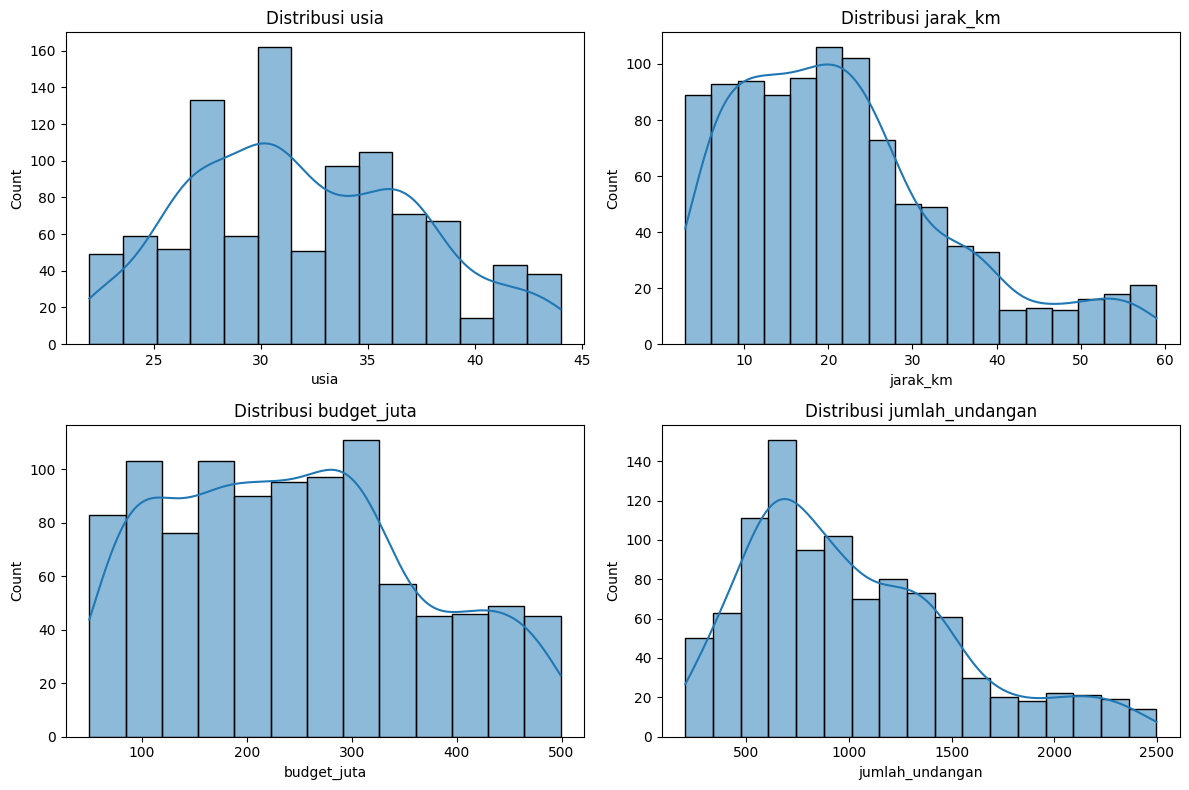

In [2]:
kolom_kategorik = ['jenis_venue', 'musim_nikah', 'level_catering', 'jenis_dekorasi', 'deal_jadi']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, kolom in zip(axes.ravel(), ['usia', 'jarak_km', 'budget_juta', 'jumlah_undangan']):
    sns.histplot(df[kolom], kde=True, ax=ax)
    ax.set_title(f'Distribusi {kolom}')
plt.tight_layout()
plt.show()

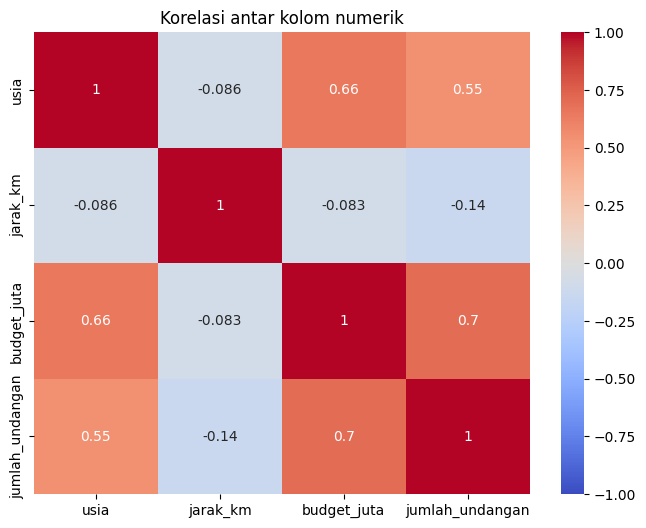

In [3]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    df[['usia', 'jarak_km', 'budget_juta', 'jumlah_undangan']].corr(),
    annot=True, cmap='coolwarm', vmin=-1, vmax=1
)
plt.title('Korelasi antar kolom numerik')
plt.show()

In [4]:
df['kategori_usia'] = pd.cut(
    df['usia'],
    bins=[0, 30, 40, 100],
    labels=['Muda', 'Dewasa', 'Senior']
)

df['kategori_jarak'] = pd.cut(
    df['jarak_km'],
    bins=[0, 10, 30, 100],
    labels=['Dekat', 'Sedang', 'Jauh']
)

fitur_biner = pd.get_dummies(
    df[['kategori_usia', 'kategori_jarak', 'jenis_venue', 'musim_nikah', 'level_catering', 'jenis_dekorasi']],
    dtype=int
)

fitur_numerik = df[['budget_juta', 'jumlah_undangan']]

X = pd.concat([fitur_numerik, fitur_biner], axis=1)
print("Jumlah fitur setelah encoding:", X.shape[1])
X.head()

Jumlah fitur setelah encoding: 22


,budget_juta,jumlah_undangan,kategori_usia_Muda,kategori_usia_Dewasa,kategori_usia_Senior,kategori_jarak_Dekat,kategori_jarak_Sedang,kategori_jarak_Jauh,jenis_venue_Gedung,jenis_venue_Indoor,...,musim_nikah_Akhir_Tahun,musim_nikah_Hujan,musim_nikah_Kemarau,level_catering_Basic,level_catering_Gold,level_catering_Platinum,level_catering_Silver,jenis_dekorasi_Minimalis,jenis_dekorasi_Modern_Mewah,jenis_dekorasi_Rustic
0,92,538,1,0,0,0,1,0,0,0,...,0,0,1,0,0,0,1,0,0,1
1,66,495,1,0,0,0,0,1,0,0,...,0,1,0,1,0,0,0,0,0,1
2,118,421,1,0,0,1,0,0,0,0,...,0,1,0,1,0,0,0,0,0,1
3,71,679,1,0,0,1,0,0,0,0,...,0,1,0,1,0,0,0,0,0,1
4,283,960,1,0,0,0,1,0,0,1,...,0,0,1,0,1,0,0,1,0,0


In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Bentuk data setelah scaling:", X_scaled.shape)

Bentuk data setelah scaling: (1000, 22)


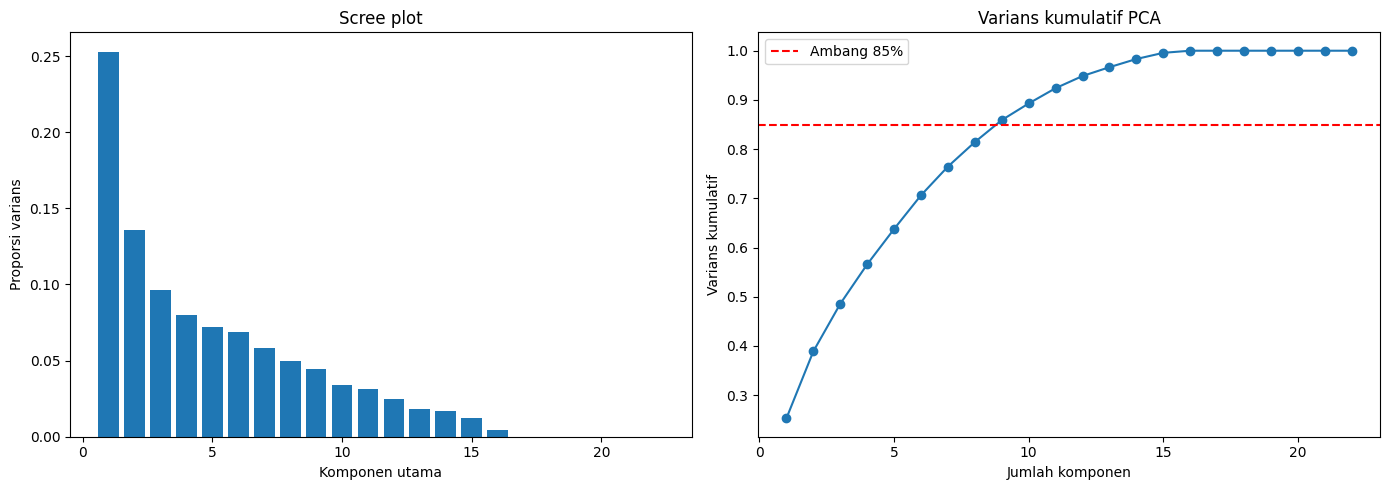

In [6]:
pca = PCA()
pca.fit(X_scaled)

proporsi_varians = pca.explained_variance_ratio_
varians_kumulatif = np.cumsum(proporsi_varians)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(range(1, len(proporsi_varians) + 1), proporsi_varians)
axes[0].set_xlabel('Komponen utama')
axes[0].set_ylabel('Proporsi varians')
axes[0].set_title('Scree plot')

axes[1].plot(range(1, len(varians_kumulatif) + 1), varians_kumulatif, marker='o')
axes[1].axhline(0.85, color='red', linestyle='--', label='Ambang 85%')
axes[1].set_xlabel('Jumlah komponen')
axes[1].set_ylabel('Varians kumulatif')
axes[1].legend()
axes[1].set_title('Varians kumulatif PCA')

plt.tight_layout()
plt.show()

In [7]:
n_komponen = int(np.argmax(varians_kumulatif >= 0.85)) + 1
print(f"Jumlah komponen untuk mencapai 85% varians: {n_komponen}")

pca = PCA(n_components=n_komponen)
X_pca = pca.fit_transform(X_scaled)

print("Bentuk data setelah PCA:", X_pca.shape)

Jumlah komponen untuk mencapai 85% varians: 9
Bentuk data setelah PCA: (1000, 9)


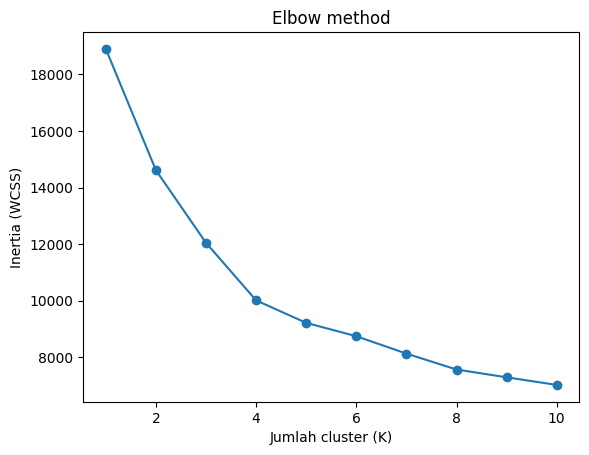

In [8]:
inertia = []
rentang_k = range(1, 11)

for k in rentang_k:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_pca)
    inertia.append(km.inertia_)

plt.plot(rentang_k, inertia, marker='o')
plt.xlabel('Jumlah cluster (K)')
plt.ylabel('Inertia (WCSS)')
plt.title('Elbow method')
plt.show()

K = 2: silhouette = 0.2400
K = 3: silhouette = 0.2260
K = 4: silhouette = 0.2722
K = 5: silhouette = 0.2787
K = 6: silhouette = 0.2576
K = 7: silhouette = 0.2340
K = 8: silhouette = 0.2336
K = 9: silhouette = 0.2315
K = 10: silhouette = 0.2338


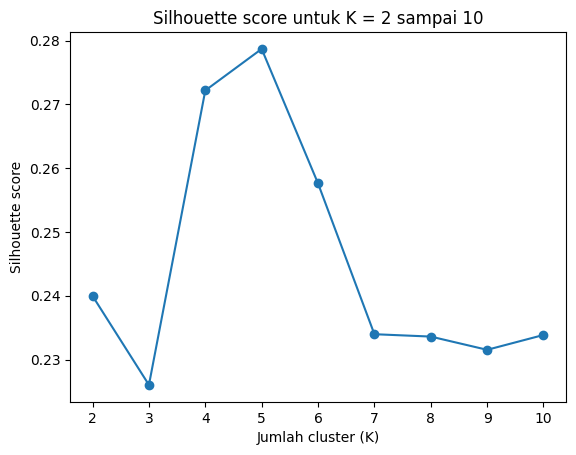

In [9]:
skor_silhouette = []

for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    label = km.fit_predict(X_pca)
    skor = silhouette_score(X_pca, label)
    skor_silhouette.append(skor)
    print(f"K = {k}: silhouette = {skor:.4f}")

plt.plot(range(2, 11), skor_silhouette, marker='o')
plt.xlabel('Jumlah cluster (K)')
plt.ylabel('Silhouette score')
plt.title('Silhouette score untuk K = 2 sampai 10')
plt.show()

In [10]:
K = 4
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_pca)

print("Jumlah anggota per cluster:")
print(df['cluster'].value_counts().sort_index())

Jumlah anggota per cluster:
cluster
0    250
1    246
2    250
3    254
Name: count, dtype: int64


In [11]:
profil_numerik = df.groupby('cluster')[['usia', 'jarak_km', 'budget_juta', 'jumlah_undangan']].mean().round(1)
print("Rata-rata fitur numerik per cluster:")
profil_numerik

Rata-rata fitur numerik per cluster:


,usia,jarak_km,budget_juta,jumlah_undangan
cluster,,,,
0,37.6,16.9,404.0,1635.6
1,26.6,21.4,97.9,519.7
2,32.3,34.8,251.5,954.1
3,31.6,13.7,224.3,971.6


In [12]:
for kolom in ['jenis_venue', 'musim_nikah', 'level_catering', 'jenis_dekorasi', 'kategori_usia', 'kategori_jarak']:
    print(f"\nProporsi {kolom} per cluster:")
    print(pd.crosstab(df['cluster'], df[kolom], normalize='index').round(2))


Proporsi jenis_venue per cluster:
jenis_venue  Gedung  Indoor  Outdoor  Pantai
cluster                                     
0              0.50    0.00     0.00     0.5
1              0.00    0.00     1.00     0.0
2              0.00    0.00     0.00     1.0
3              0.48    0.51     0.02     0.0

Proporsi musim_nikah per cluster:
musim_nikah  Akhir_Tahun  Hujan  Kemarau
cluster                                 
0                   0.46   0.00     0.54
1                   0.00   0.44     0.56
2                   0.48   0.00     0.52
3                   0.00   0.56     0.44

Proporsi level_catering per cluster:
level_catering  Basic  Gold  Platinum  Silver
cluster                                      
0                 0.0  0.51      0.49    0.00
1                 0.5  0.00      0.00    0.50
2                 0.0  0.43      0.00    0.57
3                 0.0  0.51      0.00    0.49

Proporsi jenis_dekorasi per cluster:
jenis_dekorasi  Minimalis  Modern_Mewah  Rustic
cluster       

In [13]:
print("Proporsi deal_jadi per cluster:")
print(pd.crosstab(df['cluster'], df['deal_jadi'], normalize='index').round(3))

Proporsi deal_jadi per cluster:
deal_jadi      0      1
cluster                
0          0.136  0.864
1          0.488  0.512
2          0.356  0.644
3          0.295  0.705


In [14]:
tingkat_deal = df.groupby('cluster')['deal_jadi'].mean().sort_values(ascending=False)
print("\nRata-rata deal per cluster:")
print(tingkat_deal.round(3))


Rata-rata deal per cluster:
cluster
0    0.864
3    0.705
2    0.644
1    0.512
Name: deal_jadi, dtype: float64


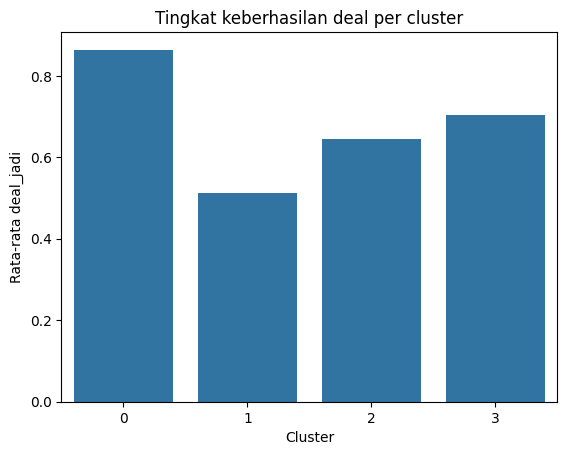

In [15]:
sns.barplot(x=tingkat_deal.index, y=tingkat_deal.values)
plt.xlabel('Cluster')
plt.ylabel('Rata-rata deal_jadi')
plt.title('Tingkat keberhasilan deal per cluster')
plt.show()

In [16]:
from scipy.stats import chi2_contingency

tabel = pd.crosstab(df['cluster'], df['deal_jadi'])
print("Tabel kontingensi cluster x deal_jadi:")
print(tabel)

chi2, p, dof, expected = chi2_contingency(tabel)

n = tabel.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(tabel.shape) - 1)))

print(f"\nChi-square = {chi2:.2f}")
print(f"Derajat bebas = {dof}")
print(f"p-value = {p:.4f}")
print(f"Cramer's V = {cramers_v:.3f}")

if p < 0.05 and cramers_v >= 0.3:
    print("Segmentasi LAYAK: perbedaan deal antar cluster kuat dan signifikan secara statistik.")
elif p < 0.05 and cramers_v >= 0.1:
    print("Segmentasi CUKUP LAYAK: signifikan, tetapi efeknya moderat.")
else:
    print("Segmentasi TIDAK LAYAK: tidak ada perbedaan deal yang signifikan antar cluster.")

Tabel kontingensi cluster x deal_jadi:
deal_jadi    0    1
cluster            
0           34  216
1          120  126
2           89  161
3           75  179

Chi-square = 73.16
Derajat bebas = 3
p-value = 0.0000
Cramer's V = 0.270
Segmentasi CUKUP LAYAK: signifikan, tetapi efeknya moderat.
